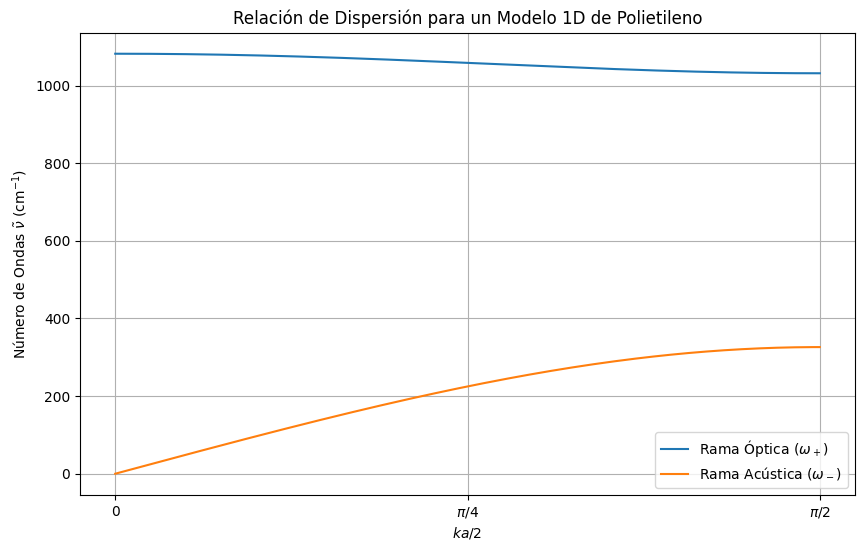

Parametros utilizados:
M = 2.329e-26 kg
a = 1.540e-10 m
K1 = 440.0 N/m
K2 = 44.0 N/m

Frecuencias características (cm^-1):
Rama optica en ka/2 = 0: 1082.29 cm^-1
Rama acustica en ka/2 = 0: 0.00 cm^-1
Rama superior en ka/2 = pi/2: 1031.93 cm^-1
Rama inferior en ka/2 = pi/2: 326.32 cm^-1
Valor esperado (teórico) para rama superior en ka/2 = pi/2: 1031.93 cm^-1
Valor esperado (teórico) para rama inferior en ka/2 = pi/2: 326.32 cm^-1


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parametros para polietileno
M_amu = 14.026  # masa de CH2 en amu
M_kg = M_amu * 1.66054e-27  # kg

K1_Nm = 440.0  # N/m (constante de fuerza C-C stretching)
K2_Nm = 44.0   # N/m (constante de fuerza más débil, K1/10)

# Constante a en la formula (distancia C-C)
a_A = 1.54  # Angstroms
a_m = a_A * 1e-10 # metros

# Velocidad de la luz en cm/s
c_cm_s = 2.99792458e10

# Termino ka/2, lo llamaremos x_axis_val. Varia de 0 a pi/2.
x_axis_val = np.linspace(0, np.pi/2, 200)

# Calculo de omega^2
term_factor = (K1_Nm + K2_Nm) / M_kg
term_sqrt_coeff = (4 * K1_Nm * K2_Nm) / ((K1_Nm + K2_Nm)**2)

sqrt_argument = 1 - term_sqrt_coeff * (np.sin(x_axis_val)**2)
sqrt_argument[sqrt_argument < 0] = 0

sqrt_term = np.sqrt(sqrt_argument)

omega_sq_plus = term_factor * (1 + sqrt_term)
omega_sq_minus = term_factor * (1 - sqrt_term)

# omega (en rad/s)
omega_plus_rad_s = np.sqrt(omega_sq_plus)
omega_minus_rad_s = np.sqrt(omega_sq_minus)

# Conversion a numero de ondas (cm^-1)
# nu_cm_inv = omega_rad_s / (2 * pi * c_cm_s)
omega_plus_cm_inv = omega_plus_rad_s / (2 * np.pi * c_cm_s)
omega_minus_cm_inv = omega_minus_rad_s / (2 * np.pi * c_cm_s)

# Grafica
plt.figure(figsize=(10, 6))
plt.plot(x_axis_val, omega_plus_cm_inv, label='Rama Óptica ($\omega_+$)')
plt.plot(x_axis_val, omega_minus_cm_inv, label='Rama Acústica ($\omega_-$)')

plt.xlabel('$ka/2$')
plt.ylabel('Número de Ondas $\\tilde{\\nu}$ (cm$^{-1}$)') # Etiqueta actualizada
plt.title('Relación de Dispersión para un Modelo 1D de Polietileno')
plt.xticks([0, np.pi/4, np.pi/2], ['0', '$\pi/4$', '$\pi/2$'])
plt.grid(True)
plt.legend()
plt.show()

# Imprimir valores caracteristicos calculados para verificacion
print(f"Parametros utilizados:")
print(f"M = {M_kg:.3e} kg")
print(f"a = {a_m:.3e} m")
print(f"K1 = {K1_Nm} N/m")
print(f"K2 = {K2_Nm} N/m")
print("\nFrecuencias características (cm^-1):")
print(f"Rama optica en ka/2 = 0: {omega_plus_cm_inv[0]:.2f} cm^-1")
print(f"Rama acustica en ka/2 = 0: {omega_minus_cm_inv[0]:.2f} cm^-1")
print(f"Rama superior en ka/2 = pi/2: {omega_plus_cm_inv[-1]:.2f} cm^-1")
print(f"Rama inferior en ka/2 = pi/2: {omega_minus_cm_inv[-1]:.2f} cm^-1")

# Verificacion de los valores esperados en k=pi/a (x=pi/2) en cm^-1
omega_expected_upper_pi_a_cm_inv = np.sqrt(2*K1_Nm/M_kg) / (2 * np.pi * c_cm_s)
omega_expected_lower_pi_a_cm_inv = np.sqrt(2*K2_Nm/M_kg) / (2 * np.pi * c_cm_s)
print(f"Valor esperado (teórico) para rama superior en ka/2 = pi/2: {omega_expected_upper_pi_a_cm_inv:.2f} cm^-1")
print(f"Valor esperado (teórico) para rama inferior en ka/2 = pi/2: {omega_expected_lower_pi_a_cm_inv:.2f} cm^-1")

--- Resultados de la Regresión Lineal para la Curva de Calibración ---
Datos de entrada (Concentración M): [1.0e-04 7.5e-05 1.5e-04]
Datos de entrada (Absorbancia): [0.58723 0.11951 0.57701]
------------------------------------------------------------
Pendiente (m): 5199.371428571431
Intercepto (b): -0.13534857142857165
Coeficiente de correlación (r): 0.7432679130992228
Coeficiente de determinación (R^2): 0.5524471906428738
Error estándar de la pendiente: 4679.803333387383
------------------------------------------------------------

Ecuación de la Curva de Calibración:
Absorbancia = 5199.3714 * [FeNCS2+] + -0.1353


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.11/dist-packages/matplotlib/pyplot.py'>

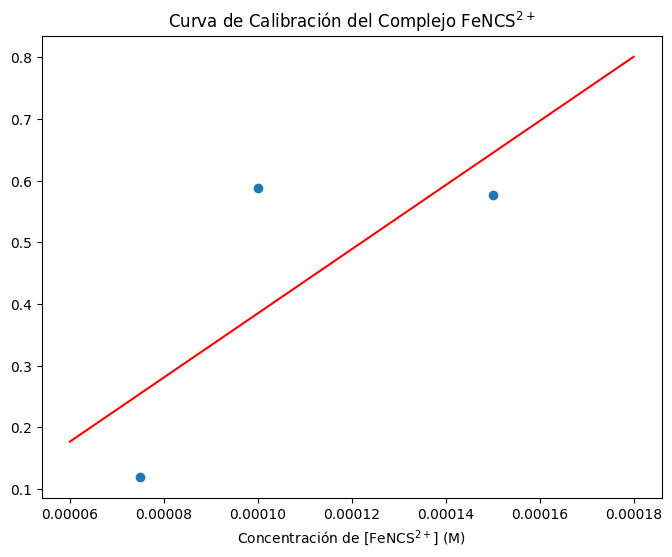

In [ ]:
import numpy as np
from scipy.stats import linregress
import matplotlib.pyplot as plt # Opcional: para graficar la curva

# Datos para la curva de calibración
# x_data: Concentración de [FeNCS2+] en M
# y_data: Absorbancia medida

x_data = np.array([0.00010, 0.000075, 0.00015])
y_data = np.array([0.58723, 0.11951, 0.57701])

# Realizar la regresión lineal
# linregress devuelve: pendiente, intercepto, coeficiente de correlación (r),
# valor p, error estándar de la pendiente
slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)

# Calcular el coeficiente de determinación (R^2)
r_squared = r_value**2

# --- Imprimir los resultados ---
print("--- Resultados de la Regresión Lineal para la Curva de Calibración ---")
print(f"Datos de entrada (Concentración M): {x_data}")
print(f"Datos de entrada (Absorbancia): {y_data}")
print("-" * 60)
print(f"Pendiente (m): {slope}")
print(f"Intercepto (b): {intercept}")
print(f"Coeficiente de correlación (r): {r_value}")
print(f"Coeficiente de determinación (R^2): {r_squared}")
print(f"Error estándar de la pendiente: {std_err}")
print("-" * 60)

# Ecuación de la línea de mejor ajuste (Curva de Calibración)
# La forma es Absorbancia = m * [FeNCS2+] + b
print("\nEcuación de la Curva de Calibración:")
print(f"Absorbancia = {slope:.4f} * [FeNCS2+] + {intercept:.4f}")

# --- Opcional: Graficar la curva de calibración ---
plt.figure(figsize=(8, 6))
plt.scatter(x_data, y_data, label='Puntos Experimentales')
# Crear puntos para dibujar la línea de regresión
x_line = np.linspace(min(x_data) * 0.8, max(x_data) * 1.2, 100) # Rango un poco más amplio
y_line = slope * x_line + intercept
plt.plot(x_line, y_line, color='red', label=f'Regresión Lineal: A = {slope:.4f}C + {intercept:.4f} ($R^2$={r_squared:.3f})')

plt.title('Curva de Calibración del Complejo FeNCS$^{2+}$')
plt.xlabel('Concentración de [FeNCS$^{2+}$] (M)')
plt

In [ ]:
# supongamos que 'exp_delta' y 'exp_Omega' contienen los puntos digitalizados:
plt.plot(theo_delta, theo_Omega_opt, '-', label='Teoría óptica')
plt.plot(theo_delta, theo_Omega_ac , '-', label='Teoría acústica')
plt.scatter(exp_delta5, exp_Omega5, marker='o', color='C2', label='Exp. ν₅ (óptica)')
plt.scatter(exp_delta9, exp_Omega9, marker='s', color='C3', label='Exp. ν₉ (acústica)')


NameError: name 'theo_delta' is not defined

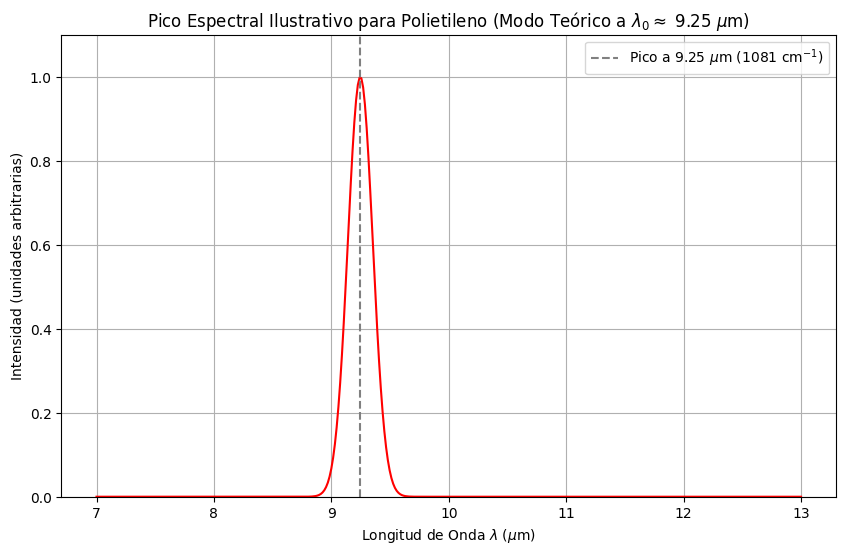

Pico ilustrativo centrado en:
Numero de ondas: 1081.48 cm^-1
Longitud de onda: 9.25 micrometros


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Frecuencia del modo optico en k=0 calculada previamente (en cm^-1)
nu_op_k0_cm_inv = 1081.48 # cm^-1

# Convertir a longitud de onda (micrometros)
lambda0_um = 1e4 / nu_op_k0_cm_inv

# Parametros para el pico gaussiano
intensity0 = 1.0  # Intensidad maxima arbitraria
# Definimos el ancho del pico, por ejemplo, un FWHM de aprox. 0.25 um
# Esto corresponde a un FWHM de aprox 30 cm^-1 a esta longitud de onda
# FWHM = 2.355 * sigma_lambda
fwhm_lambda_um = 0.25
sigma_lambda_um = fwhm_lambda_um / 2.355

# Rango de longitudes de onda para la grafica
lambda_um_values = np.linspace(7, 13, 400) # Rango de 7 a 13 micrometros

# Funcion Gaussiana para el pico
def gaussian_peak(l, l0, I0, sigma):
    return I0 * np.exp(-((l - l0)**2) / (2 * sigma**2))

# Calcular la intensidad para cada longitud de onda
intensity_values = gaussian_peak(lambda_um_values, lambda0_um, intensity0, sigma_lambda_um)

# Grafica
plt.figure(figsize=(10, 6))
plt.plot(lambda_um_values, intensity_values, color='red')

plt.xlabel('Longitud de Onda $\lambda$ ($\mu$m)')
plt.ylabel('Intensidad (unidades arbitrarias)')
plt.title(f'Pico Espectral Ilustrativo para Polietileno (Modo Teórico a $\lambda_0 \\approx$ {lambda0_um:.2f} $\mu$m)')
plt.grid(True)
plt.ylim(0, intensity0 * 1.1) # Ajustar limite Y para mejor visualizacion
plt.axvline(lambda0_um, color='gray', linestyle='--', label=f'Pico a {lambda0_um:.2f} $\mu$m ({nu_op_k0_cm_inv:.0f} cm$^{{-1}}$)')
plt.legend()
plt.show()

print(f"Pico ilustrativo centrado en:")
print(f"Numero de ondas: {nu_op_k0_cm_inv:.2f} cm^-1")
print(f"Longitud de onda: {lambda0_um:.2f} micrometros")

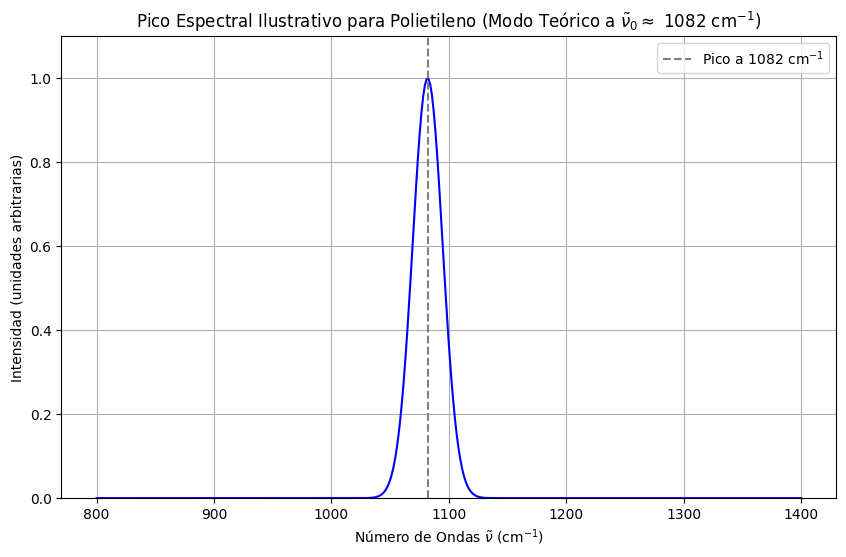

Pico ilustrativo centrado en:
Numero de ondas: 1082.00 cm^-1


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Numero de ondas del modo optico en k=0 calculado previamente (en cm^-1)
nu0_cm_inv = 1082 # cm^-1

# Parametros para el pico gaussiano
intensity0 = 1.0  # Intensidad maxima arbitraria

# Definimos el ancho del pico en cm^-1, por ejemplo, un FWHM de 30 cm^-1
fwhm_cm_inv = 30.0
sigma_cm_inv = fwhm_cm_inv / (2 * np.sqrt(2 * np.log(2))) # Aproximadamente fwhm / 2.355

# Rango de numeros de onda para la grafica
nu_cm_inv_values = np.linspace(800, 1400, 400) # Rango de 800 a 1400 cm^-1

# Funcion Gaussiana para el pico
def gaussian_peak(nu, nu0, I0, sigma):
    return I0 * np.exp(-((nu - nu0)**2) / (2 * sigma**2))

# Calcular la intensidad para cada numero de ondas
intensity_values = gaussian_peak(nu_cm_inv_values, nu0_cm_inv, intensity0, sigma_cm_inv)

# Grafica
plt.figure(figsize=(10, 6))
plt.plot(nu_cm_inv_values, intensity_values, color='blue') # Cambiado a azul para diferenciar

plt.xlabel('Número de Ondas $\\tilde{\\nu}$ (cm$^{-1}$)')
plt.ylabel('Intensidad (unidades arbitrarias)')
plt.title(f'Pico Espectral Ilustrativo para Polietileno (Modo Teórico a $\\tilde{{\\nu}}_0 \\approx$ {nu0_cm_inv:.0f} cm$^{{-1}}$)')
plt.grid(True)
plt.ylim(0, intensity0 * 1.1) # Ajustar limite Y para mejor visualizacion
plt.axvline(nu0_cm_inv, color='gray', linestyle='--', label=f'Pico a {nu0_cm_inv:.0f} cm$^{{-1}}$')
plt.legend()

# Invertir el eje x para que coincida con la convencion habitual en espectroscopia IR (opcional pero comun)
# plt.gca().invert_xaxis() # Descomentar si se prefiere el eje x invertido

plt.show()

print(f"Pico ilustrativo centrado en:")
print(f"Numero de ondas: {nu0_cm_inv:.2f} cm^-1")